In [97]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler


In [98]:
# sep='\t' : 분리형태, skiprows=1 : 1줄삭제, header=None : 컬럼제목없이
df = pd.read_csv('data/our_score.txt',sep='\t')  # ,쉼표
df.head(2)

,our,score
0,0.5,10
1,1.2,8


In [105]:
# data = df['our'].values
# label = df['score'].values
# data = df.iloc[:,0].values
data = df.iloc[:,:-1].values
label = df.iloc[:,1:].values



In [100]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [101]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)
# 데이터 예측
predict = lr.predict(test_data)
print('예측점수 : ',predict)
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측점수 :  [[46.45422474]
 [63.958542  ]
 [54.69155051]
 [40.27623042]
 [88.6705193 ]]
train 정확도 :  0.9576965064286824
test 정확도 :  0.9086768046478354


예측 점수 : [[72.19586777]]


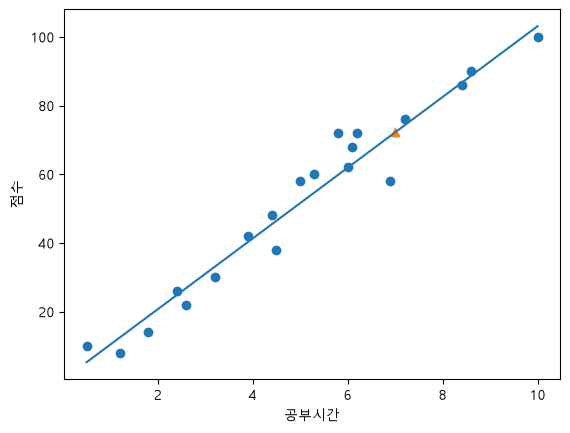

In [102]:
# 점수입력
in_data = input('공부시간을 입력하세요.>> (예: 7,10, 0.9)')
in_data = float(in_data)
result = lr.predict([[in_data]])
print("예측 점수 :",result)

# 산점도 그래프
plt.scatter(data,label)
plt.scatter(in_data,result,marker='^')
plt.plot([0.5,10],[0.5*lr.coef_[0]+lr.intercept_,10*lr.coef_[0]+lr.intercept_])
plt.xlabel('공부시간')
plt.ylabel('점수')
plt.show()